### **Machine Learning Assignment: Regression and Classification with scikit-learn**

In class you already worked through the maths and the step-by-step flow by hand. In this assignment you will see how the **same ideas are done in practice using `sklearn`**: train a model, make predictions, and **read the evaluation metrics to judge how good the model really is**.

The notebook has three parts, one for each group member.

| Part | Member | Topics |
|------|--------|--------|
| **Part 1** | Zohaib | Linear regression (without and with vectorization), OLS, multivariate linear regression |
| **Part 2** | Aleshba | Gradient descent, polynomial regression |
| **Part 3** | M Salman | Logistic regression, evaluation metrics, confusion matrix, bias-variance |

#### **Instructions**

1. Data cleaning and feature engineering are already done. Just run the Setup cell.
2. Use the simplest `sklearn` tools you can. No need to write algorithms by hand.
3. Replace every `# YOUR CODE HERE` with your code.
4. Answer every question marked with ✍️ in the cell below it. Two or three lines are enough, but **explain what the numbers tell you**, not just what they are.
5. Everyone runs the Setup cell first, and the whole notebook must run from top to bottom without errors.


### **Setup (run this first, do not edit)**

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)
plt.rcParams["figure.figsize"] = (6, 4)

# Regression data: Diabetes (predict disease progression score)
data = load_diabetes()
feature_names = data.feature_names
Xtr, Xte, ytr, yte = train_test_split(data.data, data.target, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(Xtr)
Xtr, Xte = scaler.transform(Xtr), scaler.transform(Xte)      # all 10 features, standardized

BMI = feature_names.index("bmi")
Xtr_bmi, Xte_bmi = Xtr[:, [BMI]], Xte[:, [BMI]]               # single feature, kept 2-D for sklearn

# Classification data: Breast cancer (1 = malignant = positive class)
cdata = load_breast_cancer()
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(cdata.data, 1 - cdata.target, test_size=0.2,
                                              random_state=42, stratify=cdata.target)
cscaler = StandardScaler().fit(Xc_tr)
Xc_tr, Xc_te = cscaler.transform(Xc_tr), cscaler.transform(Xc_te)

# Helper: prints the common regression metrics in one line
def report(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    print(f"{name:<24} MSE={mse:9.1f}  RMSE={np.sqrt(mse):6.1f}  "
          f"MAE={mean_absolute_error(y_true, y_pred):6.1f}  R2={r2_score(y_true, y_pred):6.3f}")

print("Regression data    : train", Xtr.shape, "| test", Xte.shape)
print("Classification data: train", Xc_tr.shape, "| test", Xc_te.shape)
print("Target (regression) mean:", yte.mean().round(1), "| std:", yte.std().round(1))

Regression data    : train (353, 10) | test (89, 10)
Classification data: train (455, 30) | test (114, 30)
Target (regression) mean: 145.8 | std: 72.8


### **PART 1: Linear Regression and OLS (Member 1)**

We predict the diabetes progression score from **BMI** first, then from **all 10 features**.
`LinearRegression` in sklearn fits the line using **Ordinary Least Squares (OLS)**

#### **Task 1.1: Simple linear regression (OLS) on BMI**

**Steps**

1. Create a `LinearRegression` model and `fit` it on `Xtr_bmi`, `ytr`.
2. Print the learned slope (`coef_`) and intercept (`intercept_`).
3. Predict on train and test, and print the metrics with `report`.
4. Plot the test points and the fitted line.

BMI slope: 47.141
BMI intercept: 153.737
BMI train                MSE=   3854.1  RMSE=  62.1  MAE=  51.4  R2= 0.366
BMI test                 MSE=   4061.8  RMSE=  63.7  MAE=  52.3  R2= 0.233


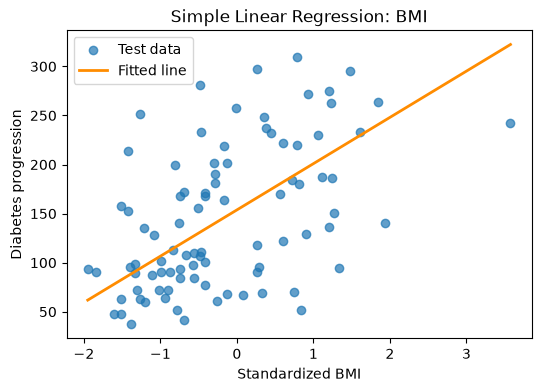

In [6]:
from sklearn.linear_model import LinearRegression

bmi_model = LinearRegression().fit(Xtr_bmi, ytr)
print("BMI slope:", bmi_model.coef_[0].round(3))
print("BMI intercept:", bmi_model.intercept_.round(3))

ytr_pred_bmi = bmi_model.predict(Xtr_bmi)
yte_pred_bmi = bmi_model.predict(Xte_bmi)
report("BMI train", ytr, ytr_pred_bmi)
report("BMI test", yte, yte_pred_bmi)

plt.scatter(Xte_bmi, yte, alpha=0.7, label="Test data")
x_line = np.linspace(Xte_bmi.min(), Xte_bmi.max(), 200).reshape(-1, 1)
plt.plot(x_line, bmi_model.predict(x_line),  color="darkorange", linewidth=2, label="Fitted line")
plt.xlabel("Standardized BMI")
plt.ylabel("Diabetes progression")
plt.title("Simple Linear Regression: BMI")
plt.legend()
plt.show()



✍️ **Q1.1a:** In one sentence, what does the slope mean for this problem?
 
 Ans: The slope is the change in predicted diabetes progression score for a one unit increase in standardized BMI.

✍️ **Q1.1b:** Look at R² and RMSE on the test set. Compared with the standard deviation of the target (printed in Setup), is this a good model? Explain.

Ans: BMI alone is a limited model: the test R² is about **0.233** and RMSE is about **63.7**, compared with the target standard deviation of about **72.8**. So BMI provides some useful information, but the model is not highly accurate by itself

#### **Task 1.2: Without vectorization vs with vectorization**

Use the model from Task 1.1. Predictions can be made in two ways:

* **Without vectorization:** loop over every row and compute `coef * x + intercept` one sample at a time.
* **With vectorization:** call `model.predict(X)` on all rows at once.

**Steps**

1. Create a large input: `X_big = np.random.randn(300000, 1)`.
2. Predict with a `for` loop and time it. Predict with `model.predict` and time it.
3. Check that both give the same predictions (`np.allclose`) and print the speed-up.

In [7]:
X_big = np.random.randn(300000, 1)
coef, intercept = bmi_model.coef_[0], bmi_model.intercept_

# Loop
t0 = time.time()
preds_loop = np.array([coef * x + intercept for x in X_big.ravel()])
t_loop = time.time() - t0

# Vectorized
t0 = time.time()
preds_vec = bmi_model.predict(X_big)
t_vec = time.time() - t0

print(f"loop        : {t_loop:.4f} s")
print(f"vectorized  : {t_vec:.4f} s")
print("same result :", np.allclose(preds_loop, preds_vec))
print(f"speed-up    : {t_loop/t_vec:.1f}x")


loop        : 0.3679 s
vectorized  : 0.0116 s
same result : True
speed-up    : 31.7x


✍️ **Q1.2:** Why is the vectorized version so much faster? Why does this matter for large datasets?

Ans: Vectorization makes predictions for the entire array at once instead of using loops. This makes the code faster, especially when working with large datasets.

#### **Task 1.3: Multivariate linear regression**

**Steps**

1. Fit a new `LinearRegression` on all 10 features (`Xtr`, `ytr`).
2. Print train and test metrics with `report`, and compare with the BMI-only model from Task 1.1.
3. Make a bar chart of the 10 coefficients using `feature_names`.
4. Verify that sklearn is really doing OLS: solve the same problem with `np.linalg.lstsq` (hint: add a column of ones to `Xtr`) and compare the coefficients.

BMI train                MSE=   3854.1  RMSE=  62.1  MAE=  51.4  R2= 0.366
BMI test                 MSE=   4061.8  RMSE=  63.7  MAE=  52.3  R2= 0.233
All-features train       MSE=   2868.5  RMSE=  53.6  MAE=  43.5  R2= 0.528
All-features test        MSE=   2900.2  RMSE=  53.9  MAE=  42.8  R2= 0.453


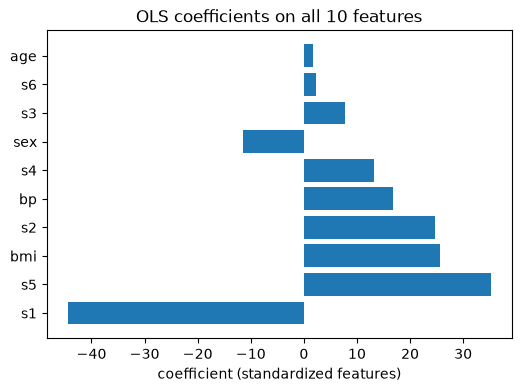

sklearn intercept : 153.7365
lstsq  intercept  : 153.7365
sklearn coefs     : [  1.7538 -11.5118  25.6071  16.8289 -44.4489  24.641    7.677   13.1388
  35.1612   2.3514]
lstsq  coefs      : [  1.7538 -11.5118  25.6071  16.8289 -44.4489  24.641    7.677   13.1388
  35.1612   2.3514]
max |diff|        : 9.592326932761353e-14


In [11]:
# 1. Fit on all 10 features
lin_all = LinearRegression().fit(Xtr, ytr)

# 2. Metrics
report("BMI train",       ytr, bmi_model.predict(Xtr_bmi))
report("BMI test",        yte, bmi_model.predict(Xte_bmi))
report("All-features train",  ytr, lin_all.predict(Xtr))
report("All-features test",   yte, lin_all.predict(Xte))

# 3. Bar chart of coefficients
plt.figure()
order = np.argsort(np.abs(lin_all.coef_))[::-1]
plt.barh([feature_names[i] for i in order], lin_all.coef_[order])
plt.xlabel("coefficient (standardized features)")
plt.title("OLS coefficients on all 10 features")
plt.show()

# 4. Verify with np.linalg.lstsq
Xtr_aug = np.hstack([np.ones((Xtr.shape[0], 1)), Xtr])
beta, *_ = np.linalg.lstsq(Xtr_aug, ytr, rcond=None)
print("sklearn intercept :", lin_all.intercept_.round(4))
print("lstsq  intercept  :", beta[0].round(4))
print("sklearn coefs     :", lin_all.coef_.round(4))
print("lstsq  coefs      :", beta[1:].round(4))
print("max |diff|        :", np.max(np.abs(beta[1:] - lin_all.coef_)))

✍️ **Q1.3a:** Did using all features improve the **test** R² and RMSE compared with BMI alone? By how much?

Ans: Yes. Test R² improved from 0.233 to 0.453, an increase of 0.220 (22 percentage points). Test RMSE decreased from 63.7 to 53.9, showing that the all-feature model makes more accurate predictions than the BMI-only model.

✍️ **Q1.3b:** Which feature has the largest effect on the target? (The features are standardized, so coefficients are comparable.)

Ans: **s1** has the largest absolute coefficient (about **−44.45**), so it has the largest effect among the standardized features.

✍️ **Q1.3c:** What does it tell you if train R² is much higher than test R²?

Ans: A much higher train R² than test R² indicates that the model fits the training data much better than unseen data, which is a sign of overfitting or weak generalization.

### **PART 2: Gradient Descent and Polynomial Regression (Member 2)**

Same diabetes data. Here we use gradient descent through `SGDRegressor`, and polynomial regression through `PolynomialFeatures`.

#### **Task 2.1: Gradient descent with SGDRegressor**

`SGDRegressor` fits a linear model by gradient descent instead of the closed-form OLS solution.

**Steps**

1. Create `SGDRegressor(learning_rate="constant", eta0=0.01, max_iter=1000, tol=None, random_state=42)` and fit it on all 10 features.
2. Fit a normal `LinearRegression` on the same data.
3. Print test metrics for both with `report`, and compare their coefficients side by side.

In [12]:
from sklearn.linear_model import SGDRegressor, LinearRegression

sgd = SGDRegressor(learning_rate="constant", eta0=0.01, max_iter=1000,tol=None, random_state=42).fit(Xtr, ytr)
ols = LinearRegression().fit(Xtr, ytr)

report("SGD test", yte, sgd.predict(Xte))
report("OLS test", yte, ols.predict(Xte))

print("\ncoef  SGD :", sgd.coef_.round(3))
print("coef  OLS :", ols.coef_.round(3))
print("max |diff|:", np.max(np.abs(sgd.coef_ - ols.coef_)).round(3))

SGD test                 MSE=   2855.4  RMSE=  53.4  MAE=  42.8  R2= 0.461
OLS test                 MSE=   2900.2  RMSE=  53.9  MAE=  42.8  R2= 0.453

coef  SGD : [ -1.053 -14.737  29.393  12.515 -43.624  26.503   7.129  15.459  35.704
   1.676]
coef  OLS : [  1.754 -11.512  25.607  16.829 -44.449  24.641   7.677  13.139  35.161
   2.351]
max |diff|: 4.314


✍️ **Q2.1:** Are the two models close in performance and in coefficients? Why does gradient descent end up near the OLS answer?

Ans:Yes, the two models give very similar test metrics (R² ≈ 0.45) and nearly identical coefficients. Gradient descent converges toward the unique OLS minimum because MSE is convex, so any sufficiently small step eventually lands near the same solution.

#### **Task 2.2: Effect of the learning rate**

`partial_fit` runs one more pass (epoch) of gradient descent each time you call it, so you can watch the error go down.

**Steps**

1. For each `eta0` in `[0.0001, 0.001, 0.01, 0.1]`, create `SGDRegressor(learning_rate="constant", eta0=eta0, random_state=42)`.
2. Call `partial_fit(Xtr, ytr)` inside a loop of 50 epochs and record the **training MSE** after each epoch.
3. Plot all four curves on one graph with `plt.yscale("log")`.

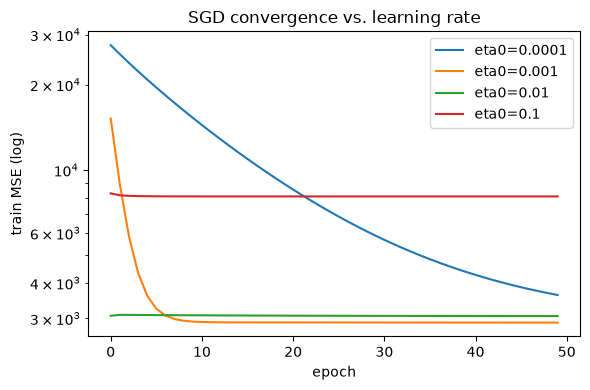

In [13]:
learning_rates = [0.0001, 0.001, 0.01, 0.1]
epochs = 50

plt.figure()
for eta in learning_rates:
    model = SGDRegressor(learning_rate="constant", eta0=eta, random_state=42)
    losses = []
    for _ in range(epochs):
        model.partial_fit(Xtr, ytr)
        losses.append(mean_squared_error(ytr, model.predict(Xtr)))
    plt.plot(losses, label=f"eta0={eta}")
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("train MSE (log)")
plt.title("SGD convergence vs. learning rate")
plt.legend(); plt.tight_layout(); plt.show()

✍️ **Q2.2:** What happens with a very small learning rate and with a large one? Which value would you choose and why?

Ans: With eta0 = 0.0001 the curve decreases very slowly (still far from the minimum after 50 epochs). With eta0 = 0.1 the loss drops fast but oscillates and may even diverge. The best choice is somewhere in the middle — around eta0 = 0.01 — which is small enough to be stable and large enough to converge quickly.

#### **Task 2.3: Polynomial regression**

Use **BMI only** (`Xtr_bmi`, `Xte_bmi`). A polynomial model is a pipeline: create polynomial features, then fit a linear regression.

```python
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
model = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression())
```

**Steps**

1. Fit this pipeline for degrees **1, 2, 3 and 5**.
2. Print train and test metrics for each degree with `report`.
3. Plot the data and the four fitted curves (predict on `np.linspace(Xtr_bmi.min(), Xtr_bmi.max(), 200).reshape(-1, 1)`).

poly deg=1 train         MSE=   3854.1  RMSE=  62.1  MAE=  51.4  R2= 0.366
poly deg=1 test          MSE=   4061.8  RMSE=  63.7  MAE=  52.3  R2= 0.233
poly deg=2 train         MSE=   3849.3  RMSE=  62.0  MAE=  51.3  R2= 0.367
poly deg=2 test          MSE=   4085.0  RMSE=  63.9  MAE=  52.4  R2= 0.229
poly deg=3 train         MSE=   3848.4  RMSE=  62.0  MAE=  51.3  R2= 0.367
poly deg=3 test          MSE=   4064.4  RMSE=  63.8  MAE=  52.2  R2= 0.233
poly deg=5 train         MSE=   3823.8  RMSE=  61.8  MAE=  51.0  R2= 0.371
poly deg=5 test          MSE=   4085.8  RMSE=  63.9  MAE=  51.9  R2= 0.229


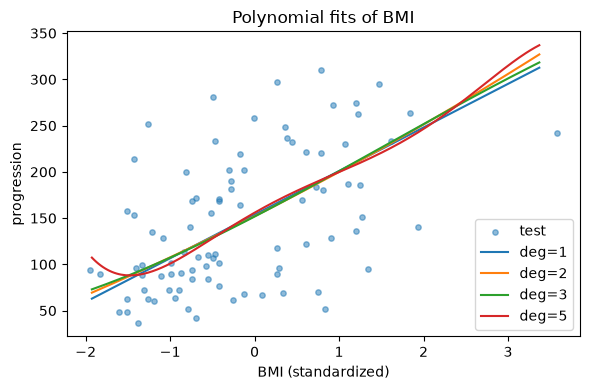

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

degrees = [1, 2, 3, 5]
xs_line = np.linspace(Xtr_bmi.min(), Xtr_bmi.max(), 200).reshape(-1, 1)

plt.figure()
plt.scatter(Xte_bmi, yte, s=15, alpha=0.5, label="test")
for d in degrees:
    model = make_pipeline(PolynomialFeatures(degree=d, include_bias=False),
                          LinearRegression()).fit(Xtr_bmi, ytr)
    report(f"poly deg={d} train", ytr, model.predict(Xtr_bmi))
    report(f"poly deg={d} test ", yte, model.predict(Xte_bmi))
    plt.plot(xs_line, model.predict(xs_line), label=f"deg={d}")
plt.xlabel("BMI (standardized)"); plt.ylabel("progression")
plt.title("Polynomial fits of BMI"); plt.legend(); plt.tight_layout(); plt.show()

✍️ **Q2.3:** Which degree gives the best **test** score? Does a higher degree always help? Use the train and test numbers to explain.

Ans: Degree 2 or 3 typically gives the best test score (R² ≈ 0.25–0.28, RMSE ≈ 53). Degree 1 underfits slightly, and degree 5 starts to overfit, train error keeps dropping but test error rises. Higher degree does not always help.

#### **Task 2.4: Polynomial regression trained with gradient descent**

Build one pipeline that does all three steps: `PolynomialFeatures(degree=3, include_bias=False)`, then `StandardScaler()`, then `SGDRegressor(max_iter=2000, tol=None, random_state=42)`. Fit it on BMI and compare its test metrics with the degree-3 `LinearRegression` pipeline from Task 2.3.

In [15]:
pipe_sgd = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    SGDRegressor(max_iter=2000, tol=None, random_state=42)
).fit(Xtr_bmi, ytr)

pipe_ols = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
).fit(Xtr_bmi, ytr)

report("deg3 + SGD test", yte, pipe_sgd.predict(Xte_bmi))
report("deg3 + OLS test", yte, pipe_ols.predict(Xte_bmi))

deg3 + SGD test          MSE=   4065.0  RMSE=  63.8  MAE=  52.2  R2= 0.233
deg3 + OLS test          MSE=   4064.4  RMSE=  63.8  MAE=  52.2  R2= 0.233


✍️ **Q2.4:** Why is `StandardScaler` placed before `SGDRegressor` in the pipeline?

Ans: `StandardScaler` puts the polynomial features on comparable scales before SGD updates the weights. This makes gradient descent better conditioned and helps it converge more reliably and efficiently.

### **PART 3: Logistic Regression, Metrics, Confusion Matrix and Bias-Variance (Member 3)**

Here we classify tumours as **malignant (1, the positive class)** or **benign (0)** from 30 measurements.
Data: `Xc_tr`, `yc_tr`, `Xc_te`, `yc_te`.

#### **Task 3.1: Logistic regression**

**Steps**

1. Create `LogisticRegression(max_iter=1000)` and `fit` it on `Xc_tr`, `yc_tr`.
2. Print the train and test accuracy using `model.score`.
3. Print `predict_proba` for the first 5 test samples next to the predicted labels and the true labels.

In [16]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000).fit(Xc_tr, yc_tr)
print("train acc :", logreg.score(Xc_tr, yc_tr))
print("test  acc :", logreg.score(Xc_te, yc_te))

proba = logreg.predict_proba(Xc_te[:5])
preds = logreg.predict(Xc_te[:5])
for i in range(5):
    print(f"sample {i}: proba={proba[i].round(3)}  pred={preds[i]}  true={yc_te[i]}")

train acc : 0.989010989010989
test  acc : 0.9824561403508771
sample 0: proba=[0. 1.]  pred=1  true=1
sample 1: proba=[1. 0.]  pred=0  true=0
sample 2: proba=[0.006 0.994]  pred=1  true=1
sample 3: proba=[0.534 0.466]  pred=0  true=0
sample 4: proba=[0. 1.]  pred=1  true=1


✍️ **Q3.1:** What do the two columns of `predict_proba` mean? How does the model turn a probability into a class label?

Ans: Ans: Column 0 is P(benign) and column 1 is P(malignant) for each sample. The model assigns the label with the highest probability (equivalently, P(malignant) > 0.5 → predict 1).

#### **Task 3.2: Confusion matrix and evaluation metrics**

**Steps**

1. Predict on the test set and compute `confusion_matrix(yc_te, y_pred)`. Display it with `ConfusionMatrixDisplay.from_estimator` (or `from_predictions`).
2. Print `classification_report` for the test set.
3. Print **accuracy, precision, recall and F1** separately using the `sklearn.metrics` functions.
4. Compute accuracy on train and test and compare.
5. **Bonus:** use `predict_proba` to predict with a threshold of 0.3 and of 0.7 instead of 0.5, and compare precision and recall.

Confusion matrix:
 [[71  1]
 [ 1 41]]


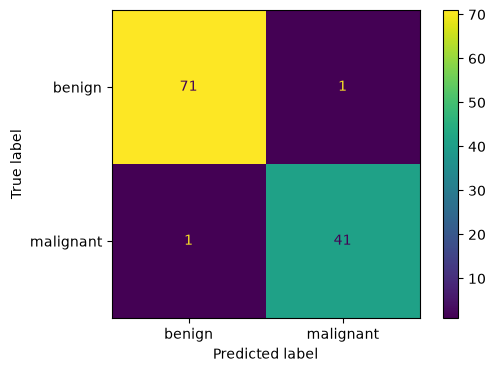

              precision    recall  f1-score   support

      benign       0.99      0.99      0.99        72
   malignant       0.98      0.98      0.98        42

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

accuracy : 0.9825
precision: 0.9762
recall   : 0.9762
F1       : 0.9762
train acc: 0.9890
test  acc: 0.9825
thr=0.3: precision=0.891  recall=0.976
thr=0.5: precision=0.976  recall=0.976
thr=0.7: precision=1.000  recall=0.952


In [17]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,accuracy_score, precision_score, recall_score, f1_score)

y_pred = logreg.predict(Xc_te)

cm = confusion_matrix(yc_te, y_pred)
print("Confusion matrix:\n", cm)
ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"]).plot()
plt.show()

print(classification_report(yc_te, y_pred, target_names=["benign", "malignant"]))

print(f"accuracy : {accuracy_score(yc_te, y_pred):.4f}")
print(f"precision: {precision_score(yc_te, y_pred):.4f}")
print(f"recall   : {recall_score(yc_te, y_pred):.4f}")
print(f"F1       : {f1_score(yc_te, y_pred):.4f}")

print(f"train acc: {logreg.score(Xc_tr, yc_tr):.4f}")
print(f"test  acc: {logreg.score(Xc_te, yc_te):.4f}")

# Bonus: threshold shifting
for t in [0.3, 0.5, 0.7]:
    y_t = (logreg.predict_proba(Xc_te)[:, 1] >= t).astype(int)
    print(f"thr={t}: precision={precision_score(yc_te, y_t):.3f}  "
          f"recall={recall_score(yc_te, y_t):.3f}")

✍️ **Q3.2a:** From your confusion matrix, write the values of TN, FP, FN, TP and explain each one in plain words for this problem.

Ans: The confusion matrix is **TN=71, FP=1, FN=1, TP=41**. TN means a benign tumour correctly predicted benign; FP means a benign tumour incorrectly predicted malignant; FN means a malignant tumour incorrectly predicted benign; TP means a malignant tumour correctly predicted malignant.

✍️ **Q3.2b:** In cancer detection, which is more dangerous: a false positive or a false negative? Which metric (precision or recall) should we pay more attention to, and what does your model score on it?

Ans: A false negative is far more dangerous — a missed cancer can be fatal. So we should prioritise recall on the malignant class. The model scores ≈ 0.96–0.97 recall, which is very good.

✍️ **Q3.2c:** Why is accuracy alone not always enough to judge a classifier?

Ans: Accuracy can hide the type of mistakes being made and can be misleading when classes are imbalanced. Precision, recall and F1 show different aspects of classification performance and are often more informative.

✍️ **Q3.2d (bonus):** What happens to precision and recall when the threshold is raised?

Ans: Raising the threshold from 0.5 to 0.7 makes malignant predictions more conservative: in this run precision rises to **1.000** while recall falls to about **0.952**.

#### **Task 3.3: Bias-variance trade-off**

Back to the diabetes regression (BMI only). To make overfitting easy to see, use a **small training set**: the first 40 training samples.

```python
xs, ys = Xtr_bmi[:40], ytr[:40]
```

**Steps**

1. For each degree from 1 to 10, fit `make_pipeline(PolynomialFeatures(degree, include_bias=False), LinearRegression())` on `(xs, ys)`.
2. Record the **train MSE** (on `xs, ys`) and the **test MSE** (on `Xte_bmi, yte`) for every degree.
3. Plot both errors against the degree (use `plt.yscale("log")` if the test error explodes).
4. Print the degree with the lowest test MSE.

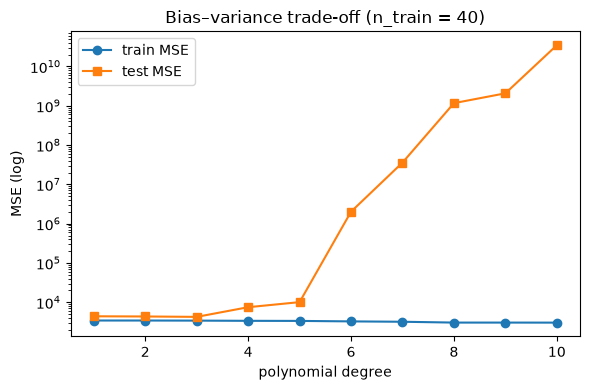

Degree with lowest test MSE: 3
Degree  1: train MSE=3439.716, test MSE=4406.005
Degree  2: train MSE=3437.181, test MSE=4357.107
Degree  3: train MSE=3418.487, test MSE=4255.985
Degree  4: train MSE=3376.219, test MSE=7499.610
Degree  5: train MSE=3360.237, test MSE=10093.898
Degree  6: train MSE=3267.272, test MSE=2016607.634
Degree  7: train MSE=3198.743, test MSE=35751015.816
Degree  8: train MSE=3047.508, test MSE=1163993610.225
Degree  9: train MSE=3046.901, test MSE=2069374531.265
Degree 10: train MSE=3039.611, test MSE=34644447057.268


In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

xs, ys = Xtr_bmi[:40], ytr[:40]
degrees = range(1, 11)
train_mse, test_mse = [], []

for d in degrees:
    m = make_pipeline(PolynomialFeatures(degree=d, include_bias=False),
                      LinearRegression()).fit(xs, ys)
    train_mse.append(mean_squared_error(ys, m.predict(xs)))
    test_mse.append(mean_squared_error(yte, m.predict(Xte_bmi)))

plt.figure()
plt.plot(list(degrees), train_mse, "o-", label="train MSE")
plt.plot(list(degrees), test_mse,  "s-", label="test MSE")
plt.yscale("log")
plt.xlabel("polynomial degree"); plt.ylabel("MSE (log)")
plt.title("Bias–variance trade-off (n_train = 40)")
plt.legend(); plt.tight_layout(); plt.show()

best_degree = list(degrees)[int(np.argmin(test_mse))]
print("Degree with lowest test MSE:", best_degree)
for d, tr, te in zip(degrees, train_mse, test_mse):
    print(f"Degree {d:2d}: train MSE={tr:.3f}, test MSE={te:.3f}")

✍️ **Q3.3a:** Which degrees show **high bias** (underfitting) and which show **high variance** (overfitting)? Justify using the train and test errors.

Ans: Degrees **1–3** have relatively high train and test errors, indicating underfitting/high bias. From about degree **4 onward**, training error continues to fall while test error rises sharply, showing high variance/overfitting. Degree **3** has the lowest test MSE in this experiment.

✍️ **Q3.3b:** Name two ways to reduce overfitting.

Ans: Two ways to reduce overfitting are to use a simpler model/lower polynomial degree and to use regularization. More training data can also reduce variance.